## Dataset Description

**Dataset Name:** Combined Cycle Power Plant (CCPP)

**Source:** UCI Machine Learning Repository.

**Dataset Link:** https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant

**Dataset Type:** Tabular Data – Supervised Learning – Regression.

**Features:**
- AT: Ambient Temperature.
- V: Exhaust Vacuum.
- AP: Ambient Pressure.
- RH: Relative Humidity.

**Target Variable:**
- PE: Net Hourly Electrical Energy Output.

**Problem Definition:**
The objective is to train a deep neural network to predict the net hourly electrical energy output (PE) using four environmental and operational input features.

**Why PE was selected as the target:**
PE is a continuous numerical variable, making it suitable for a regression problem.

# **Dataset Loading**

In [3]:
%pip install -q ucimlrepo

In [4]:

# Import libraries
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import time
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader
from ucimlrepo import fetch_ucirepo

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load Combined Cycle Power Plant dataset
power_plant = fetch_ucirepo(id=294)

# Separate input features and target variable
X = power_plant.data.features.copy()
y = power_plant.data.targets.copy()

# Combine features and target for initial inspection
df = pd.concat([X, y], axis=1)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.columns.tolist())

# Display first five rows
display(df.head())


Using device: cpu
Dataset loaded successfully!
Dataset shape: (9568, 5)

Input features:
['AT', 'V', 'AP', 'RH']

Target variable:
['PE']


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


Data Quality Assessment and Descriptive Statistics

In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nStatistical summary:")
display(df.describe())


Missing values:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Duplicate rows:
41

Data types:
AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object

Statistical summary:


,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


#Data Preprocessing

In [6]:
df = df.drop_duplicates().reset_index(drop=True)

X = df[['AT', 'V', 'AP', 'RH']].copy()
y = df[['PE']].copy()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (9527, 5)
Remaining duplicate rows: 0


# **Train / Validation / Test Split**

In [7]:

from sklearn.model_selection import train_test_split

# Split the dataset into training and temporary sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Split the temporary set into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Display dataset split shapes
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)


Training set: (6668, 4) (6668, 1)
Validation set: (1429, 4) (1429, 1)
Test set: (1430, 4) (1430, 1)


# **Feature Standardization**

In [8]:

from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform all sets
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Display the shapes
print("Training set:", X_train_scaled.shape)
print("Validation set:", X_val_scaled.shape)
print("Test set:", X_test_scaled.shape)


print("Training mean:", X_train_scaled.mean(axis=0))
print("Training std:", X_train_scaled.std(axis=0))


Training set: (6668, 4)
Validation set: (1429, 4)
Test set: (1430, 4)
Training mean: [-3.18081894e-16  1.49983338e-16 -1.50995659e-15 -2.05660990e-16]
Training std: [1. 1. 1. 1.]


In [9]:

# Convert training and validation data to PyTorch tensors

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32)

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Training tensors:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation tensors:", X_val_tensor.shape, y_val_tensor.shape)


Training dataset: 6668
Validation dataset: 1429
Training tensors: torch.Size([6668, 4]) torch.Size([6668, 1])
Validation tensors: torch.Size([1429, 4]) torch.Size([1429, 1])


# **Linear Regression Baseline**

In [10]:

import time
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Create Linear Regression model
linear_model = LinearRegression()

# Measure training time
start_time = time.perf_counter()

# Train the model
linear_model.fit(X_train_scaled, y_train)

linear_training_time = time.perf_counter() - start_time

# Make predictions
y_train_pred = linear_model.predict(X_train_scaled)
y_val_pred = linear_model.predict(X_val_scaled)

# Calculate Mean Squared Error عدلت هووون
linear_train_mse = mean_squared_error(y_train, y_train_pred)
linear_val_mse = mean_squared_error(y_val, y_val_pred)

# Display results
print("Linear Regression Results : ")
print(f"Training MSE: {linear_train_mse:.4f}")
print(f"Validation MSE: {linear_val_mse:.4f}")
print(f"Training Time: {linear_training_time:.4f} seconds")


Linear Regression Results : 
Training MSE: 20.2748
Validation MSE: 21.4396
Training Time: 0.0248 seconds


# **Baseline Deep Neural Network**

Baseline Deep Neural Network Results
Training MSE: 16.7957
Validation MSE: 18.6084
Training Time: 30.89 seconds

Linear Regression Comparison
Linear Regression Validation MSE: 21.4396
Deep Neural Network Validation MSE: 18.6084
Improvement: 13.21%


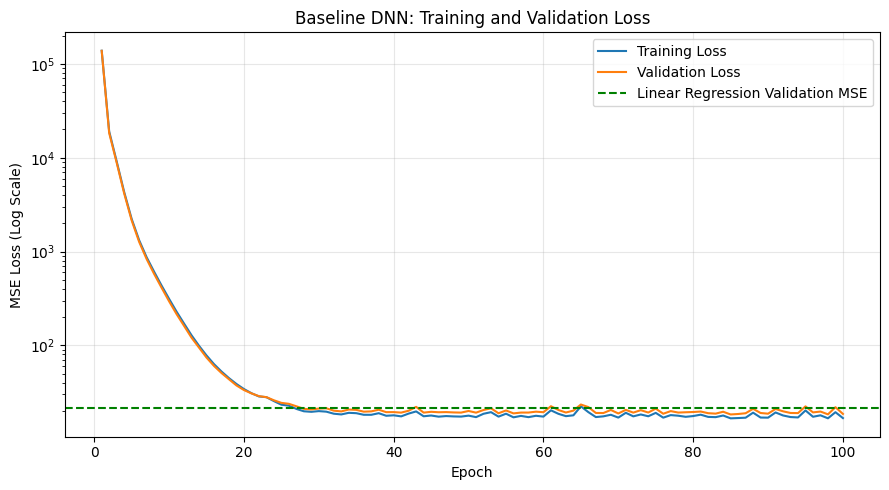

In [11]:

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time

from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")

# Prepare tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
)
y_val_tensor = torch.tensor(
    y_val.to_numpy(), dtype=torch.float32
)

# Baseline hyperparameters
hidden_layers = [64, 32]
learning_rate = 0.001
batch_size = 32
epochs = 100

# Training data loader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
)

# Deep neural network
model = nn.Sequential(
    nn.Linear(4, hidden_layers[0]),
    nn.ReLU(),
    nn.Linear(hidden_layers[0], hidden_layers[1]),
    nn.ReLU(),
    nn.Linear(hidden_layers[1], 1)
).to(device)

# Loss function and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

# Training
train_losses = []
val_losses = []

start_time = time.perf_counter()

for epoch in range(epochs):
    model.train()

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()

    model.eval()

    with torch.no_grad():
        train_predictions = model(X_train_tensor.to(device))
        val_predictions = model(X_val_tensor.to(device))

        train_loss = criterion(
            train_predictions, y_train_tensor.to(device)
        ).item()

        val_loss = criterion(
            val_predictions, y_val_tensor.to(device)
        ).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

training_time = time.perf_counter() - start_time

# Baseline results
nn_train_mse = train_losses[-1]
nn_val_mse = val_losses[-1]

print("Baseline Deep Neural Network Results")
print(f"Training MSE: {nn_train_mse:.4f}")
print(f"Validation MSE: {nn_val_mse:.4f}")
print(f"Training Time: {training_time:.2f} seconds")

print("\nLinear Regression Comparison")
print(f"Linear Regression Validation MSE: {linear_val_mse:.4f}")
print(f"Deep Neural Network Validation MSE: {nn_val_mse:.4f}")

improvement = (
    (linear_val_mse - nn_val_mse)
    / linear_val_mse
) * 100
print(f"Improvement: {improvement:.2f}%")

# Loss curves
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    label="Validation Loss"
)

plt.axhline(
    y=linear_val_mse,
    color="green",
    linestyle="--",
    label="Linear Regression Validation MSE"
)

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (Log Scale)")
plt.title("Baseline DNN: Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:
# Create comparison table automatically

comparison_df = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Deep Neural Network"
    ],

    "Training MSE": [
        linear_train_mse,
        nn_train_mse
    ],

    "Validation MSE": [
        linear_val_mse,
        nn_val_mse
    ],

    "Training Time (s)": [
        linear_training_time,
        training_time
    ]
})

display(comparison_df.round(4))

,Model,Training MSE,Validation MSE,Training Time (s)
0,Linear Regression,20.2748,21.4396,0.0248
1,Deep Neural Network,16.7957,18.6084,30.8940


## Baseline Results Comparison
**Observation**

The Deep Neural Network achieved a lower validation MSE than Linear Regression (18.6084 vs. 21.4396), reducing the validation error by approximately 13.21%.

However, Linear Regression required much less training time. This shows a trade-off between predictive performance and computational cost.

The results will serve as a baseline for evaluating the upcoming hyperparameter experiments.

# **Hyperparameter Experiments**

## <font color="#3B82F6">Learning Rate</font>



### Learning Rate Experiment 1 — LR = 0.0001

In [13]:

def run_learning_rate_experiment(lr):
    torch.manual_seed(42)
    np.random.seed(42)

    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )
 # Create a new model
    experiment_model = nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    loss_fn = nn.MSELoss()
    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(), lr=lr
    )

    training_losses = []
    validation_losses = []

    start_time = time.perf_counter()

    for epoch in range(100):
        experiment_model.train()

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            experiment_optimizer.zero_grad()
            loss = loss_fn(experiment_model(xb), yb)
            loss.backward()
            experiment_optimizer.step()

        experiment_model.eval()

        with torch.no_grad():
            train_mse_epoch = loss_fn(
                experiment_model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()

            val_mse_epoch = loss_fn(
                experiment_model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        training_losses.append(train_mse_epoch)
        validation_losses.append(val_mse_epoch)

    elapsed = time.perf_counter() - start_time

    return {
        "Learning Rate": lr,
        "Train MSE": training_losses[-1],
        "Val MSE": validation_losses[-1],
        "Time (s)": elapsed,
        "Train Losses": training_losses,
        "Val Losses": validation_losses
    }


lr_results = []

result = run_learning_rate_experiment(0.0001)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.0001
Training MSE: 31.7889
Validation MSE: 31.3234
Training Time: 28.19 seconds


### Learning Rate Experiment 2 — LR = 0.0003

In [14]:

result = run_learning_rate_experiment(0.0003)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.0003
Training MSE: 17.4802
Validation MSE: 19.0203
Training Time: 26.74 seconds


### Learning Rate Experiment 3 — LR = 0.003

In [15]:

result = run_learning_rate_experiment(0.003)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.003
Training MSE: 17.2582
Validation MSE: 19.1169
Training Time: 27.14 seconds


### Learning Rate Experiment 4 — LR = 0.01

In [16]:

result = run_learning_rate_experiment(0.01)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.01
Training MSE: 21.0044
Validation MSE: 23.7329
Training Time: 26.95 seconds


### Learning Rate Experiment 5 — LR = 0.03

In [17]:

result = run_learning_rate_experiment(0.03)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.03
Training MSE: 31.6638
Validation MSE: 35.6667
Training Time: 26.99 seconds


### Learning Rate Experiments — Results Summary

In [18]:

lr_table = pd.DataFrame([
    {
        "Run": "Baseline",
        "Learning Rate": 0.001,
        "Train MSE": nn_train_mse,
        "Val MSE": nn_val_mse,
        "Time (s)": training_time
    },
    *[
        {
            "Run": f"LR Experiment {i}",
            "Learning Rate": r["Learning Rate"],
            "Train MSE": r["Train MSE"],
            "Val MSE": r["Val MSE"],
            "Time (s)": r["Time (s)"]
        }
        for i, r in enumerate(lr_results, start=1)
    ]
])

display(lr_table.round(4))


,Run,Learning Rate,Train MSE,Val MSE,Time (s)
0,Baseline,0.0010,16.7957,18.6084,30.8940
1,LR Experiment 1,0.0001,31.7889,31.3234,28.1881
2,LR Experiment 2,0.0003,17.4802,19.0203,26.7365
3,LR Experiment 3,0.0030,17.2582,19.1169,27.1361
4,LR Experiment 4,0.0100,21.0044,23.7329,26.9548
5,LR Experiment 5,0.0300,31.6638,35.6667,26.9886


### Learning Rate — Loss Curves

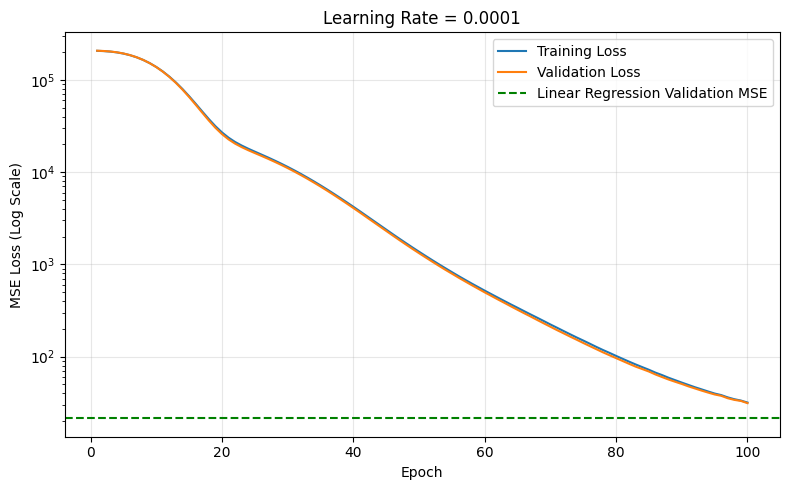

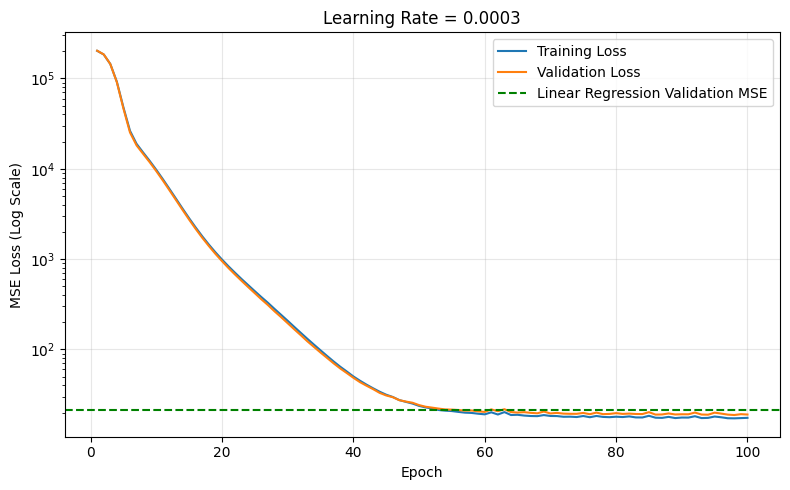

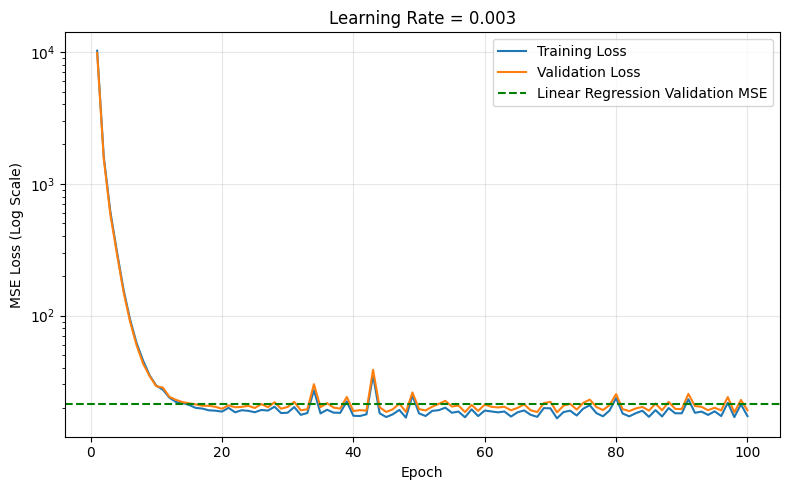

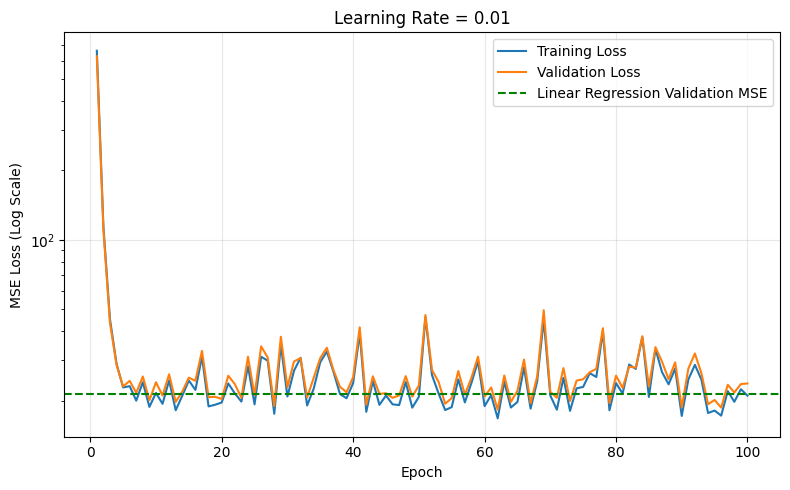

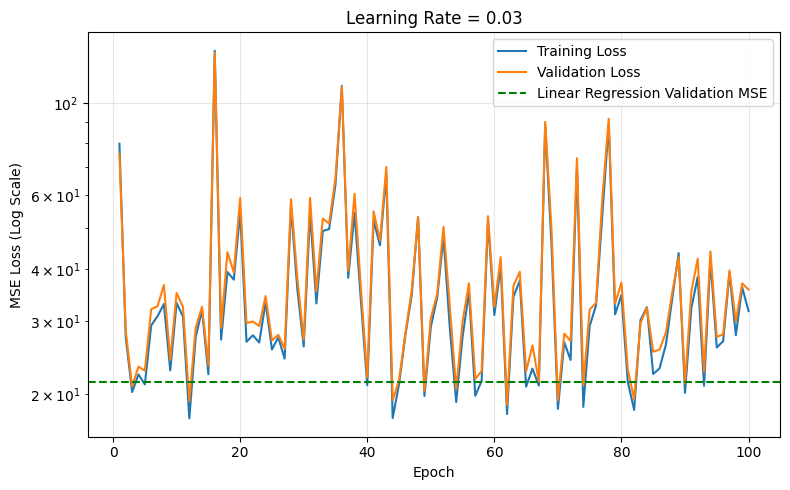

In [19]:

for r in lr_results:
    plt.figure(figsize=(8, 5))

    plt.plot(
        range(1, len(r["Train Losses"]) + 1),
        r["Train Losses"],
        label="Training Loss"
    )

    plt.plot(
        range(1, len(r["Val Losses"]) + 1),
        r["Val Losses"],
        label="Validation Loss"
    )

    plt.axhline(
        y=linear_val_mse,
        color="green",
        linestyle="--",
        label="Linear Regression Validation MSE"
    )

    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss (Log Scale)")
    plt.title(f"Learning Rate = {r['Learning Rate']}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## <font color="#3B82F6">Optimizer </font>

In [20]:
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

def run_optimizer_experiment(optimizer_name):

    # Reproducibility
    torch.manual_seed(42)
    np.random.seed(42)

    generator = torch.Generator().manual_seed(42)

    # DataLoader
    loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    # Same baseline architecture
    model = nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    # Choose optimizer
    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=0.001,
            momentum=0.0
        )

    elif optimizer_name == "SGD + Momentum":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=0.001,
            momentum=0.9
        )

    else:
        raise ValueError("Unknown optimizer")

    # Loss function
    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    start_time = time.perf_counter()

    # Training
    for epoch in range(100):

        model.train()

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

        # Evaluation
        model.eval()

        with torch.no_grad():

            train_mse = criterion(
                model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()

            val_mse = criterion(
                model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        train_losses.append(train_mse)
        val_losses.append(val_mse)

        # Stop if numerical instability occurs
        if not np.isfinite(train_mse) or not np.isfinite(val_mse):
            break

    training_time = time.perf_counter() - start_time

    # Return results
    return {
        "Optimizer": optimizer_name,
        "Learning Rate": 0.001,
        "Train MSE": train_mse,
        "Val MSE": val_mse,
        "Time (s)": training_time,
        "Epochs Completed": len(train_losses),
        "Train Losses": train_losses,
        "Val Losses": val_losses
    }

Optimizer Experiment 1 — SGD

In [21]:
# Initialize optimizer results
optimizer_results = []

# Run SGD experiment
result = run_optimizer_experiment("SGD")

# Save result
optimizer_results.append(result)

# Display results
print("Optimizer:", result["Optimizer"])
print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Optimizer: SGD
Learning Rate: 0.001
Training MSE: nan
Validation MSE: nan
Training Time: 0.18 seconds
Epochs Completed: 1


Optimizer Experiment 2 — SGD with Momentum (0.9)

In [22]:
# Optimizer Experiment 2 - SGD with Momentum

result = run_optimizer_experiment("SGD + Momentum")

optimizer_results.append(result)

print("Optimizer:", result["Optimizer"])
print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Optimizer: SGD + Momentum
Learning Rate: 0.001
Training MSE: nan
Validation MSE: nan
Training Time: 0.19 seconds
Epochs Completed: 1


Optimizer Experiments — Results Summary

In [23]:
# Compare Adam, SGD, and SGD with Momentum

import pandas as pd

comparison_df = pd.DataFrame([
    {
        "Optimizer": "Adam (Baseline)",
        "Learning Rate": 0.001,
        "Train MSE": nn_train_mse,
        "Validation MSE": nn_val_mse,
        "Training Time (s)": training_time,
        "Epochs": 100
    },

    *[
        {
            "Optimizer": r["Optimizer"],
            "Learning Rate": r["Learning Rate"],
            "Train MSE": r["Train MSE"],
            "Validation MSE": r["Val MSE"],
            "Training Time (s)": r["Time (s)"],
            "Epochs": r["Epochs Completed"]
        }

        for r in optimizer_results
        if r["Optimizer"] in ["SGD", "SGD + Momentum"]
    ]
])

# Avoid duplicate entries if a cell was rerun
comparison_df = comparison_df.drop_duplicates(
    subset=["Optimizer"],
    keep="first"
)

display(comparison_df.round(4))

,Optimizer,Learning Rate,Train MSE,Validation MSE,Training Time (s),Epochs
0,Adam (Baseline),0.001,16.7957,18.6084,30.8940,100
1,SGD,0.001,NaN,NaN,0.1760,1
2,SGD + Momentum,0.001,NaN,NaN,0.1891,1


## <font color="#3B82F6">Batch Size</font>


In [24]:
import time
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader


def run_batch_size_experiment(batch_size):

    # Reproducibility
    torch.manual_seed(42)
    np.random.seed(42)

    generator = torch.Generator().manual_seed(42)

    # DataLoader
    loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    # Same baseline model
    model = nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    # Fixed optimizer
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    # Fixed loss function
    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    start_time = time.perf_counter()

    # Training
    for epoch in range(100):

        model.train()

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

        # Evaluation
        model.eval()

        with torch.no_grad():

            train_mse = criterion(
                model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()

            val_mse = criterion(
                model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        train_losses.append(train_mse)
        val_losses.append(val_mse)

        # Check numerical stability
        if not np.isfinite(train_mse) or not np.isfinite(val_mse):
            break

    training_time = time.perf_counter() - start_time

    # Return results
    return {
        "Batch Size": batch_size,
        "Train MSE": train_mse,
        "Val MSE": val_mse,
        "Time (s)": training_time,
        "Epochs Completed": len(train_losses),
        "Train Losses": train_losses,
        "Val Losses": val_losses
    }

Batch Size Experiment 1 — BS = 16

In [25]:
# Batch Size Experiment 1 - BS = 16

batch_results = []

result = run_batch_size_experiment(16)

batch_results.append(result)

# Display results
print("Batch Size:", result["Batch Size"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Batch Size: 16
Training MSE: 18.5267
Validation MSE: 20.3375
Training Time: 48.47 seconds
Epochs Completed: 100


Batch Size Experiment 2 — BS = 24



In [26]:

result = run_batch_size_experiment(24)

batch_results.append(result)

print("Batch Size:", result["Batch Size"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Batch Size: 24
Training MSE: 16.6223
Validation MSE: 18.3728
Training Time: 34.69 seconds
Epochs Completed: 100


Batch Size Experiment 4— BS = 64

In [27]:
result = run_batch_size_experiment(64)

batch_results.append(result)

print("Batch Size:", result["Batch Size"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Batch Size: 64
Training MSE: 17.8586
Validation MSE: 19.4846
Training Time: 16.78 seconds
Epochs Completed: 100


Batch Size Experiment 5 — BS = 128

In [28]:


result = run_batch_size_experiment(128)

batch_results.append(result)

print("Batch Size:", result["Batch Size"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Batch Size: 128
Training MSE: 21.7127
Validation MSE: 22.2300
Training Time: 10.94 seconds
Epochs Completed: 100


Batch Size Experiment 6— BS = 256

In [29]:


result = run_batch_size_experiment(256)

batch_results.append(result)

print("Batch Size:", result["Batch Size"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Batch Size: 256
Training MSE: 138.2894
Validation MSE: 132.3394
Training Time: 7.09 seconds
Epochs Completed: 100


Batch Size Experiments — Results Summary

In [30]:
# Batch Size Experiments - Results Summary

batch_table = pd.DataFrame([
    {
        "Run": "Baseline",
        "Batch Size": 32,
        "Train MSE": nn_train_mse,
        "Val MSE": nn_val_mse,
        "Time (s)": training_time,
        "Epochs": 100
    },

    *[
        {
            "Run": f"Experiment {i}",
            "Batch Size": r["Batch Size"],
            "Train MSE": r["Train MSE"],
            "Val MSE": r["Val MSE"],
            "Time (s)": r["Time (s)"],
            "Epochs": r["Epochs Completed"]
        }

        for i, r in enumerate(batch_results, start=1)
    ]
])

# Remove duplicate configurations
batch_table = batch_table.drop_duplicates(
    subset=["Batch Size"],
    keep="last"
)

# Sort by batch size
batch_table = batch_table.sort_values(
    "Batch Size"
).reset_index(drop=True)

# Display table
display(batch_table.round(4))

,Run,Batch Size,Train MSE,Val MSE,Time (s),Epochs
0,Experiment 1,16,18.5267,20.3375,48.4686,100
1,Experiment 2,24,16.6223,18.3728,34.6888,100
2,Baseline,32,16.7957,18.6084,30.8940,100
3,Experiment 3,64,17.8586,19.4846,16.7759,100
4,Experiment 4,128,21.7127,22.2300,10.9387,100
5,Experiment 5,256,138.2894,132.3394,7.0867,100


Batch Size — Training and Validation Loss Curves

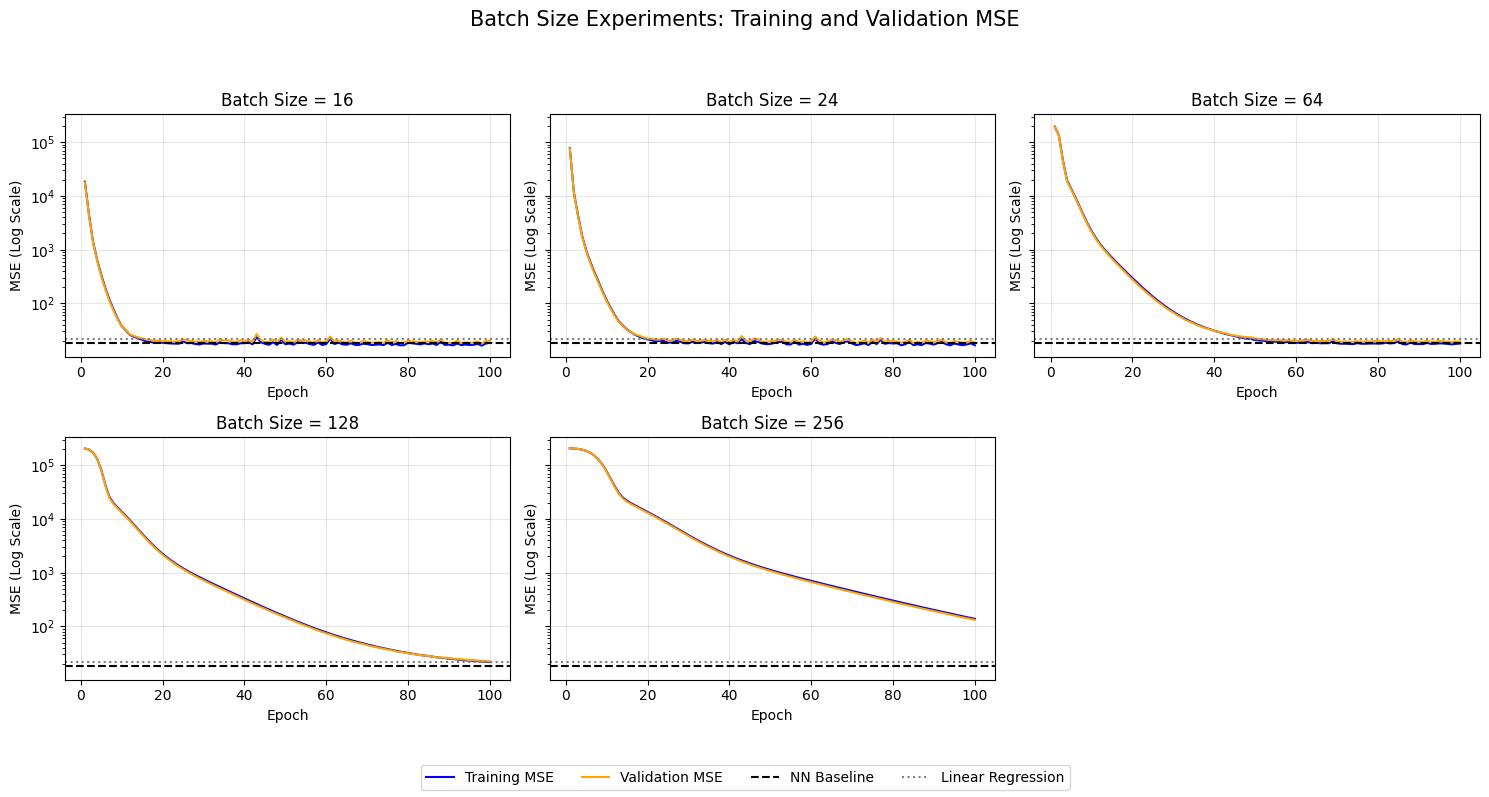

In [44]:
import matplotlib.pyplot as plt

# Batch sizes
batch_sizes = [16, 24, 64, 128, 256]

# Get results
batch_lookup = {
    r["Batch Size"]: r
    for r in batch_results
}

# Create subplots
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8),
    sharey=True
)

axes = axes.flatten()

for i, bs in enumerate(batch_sizes):

    result = batch_lookup[bs]

    epochs = range(1, len(result["Train Losses"]) + 1)

    # Training MSE
    axes[i].plot(
        epochs,
        result["Train Losses"],
        color="blue",
        label="Training MSE"
    )

    # Validation MSE
    axes[i].plot(
        epochs,
        result["Val Losses"],
        color="orange",
        label="Validation MSE"
    )

    # Neural Network baseline
    axes[i].axhline(
        nn_val_mse,
        color="black",
        linestyle="--",
        label="NN Baseline"
    )

    # Linear Regression reference
    axes[i].axhline(
        linear_val_mse,
        color="gray",
        linestyle=":",
        label="Linear Regression"
    )

    axes[i].set_title(f"Batch Size = {bs}")
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE (Log Scale)")
    axes[i].set_yscale("log")
    axes[i].grid(True, alpha=0.3)

# Hide the empty subplot
axes[5].axis("off")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4
)

fig.suptitle(
    "Batch Size Experiments: Training and Validation MSE",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()

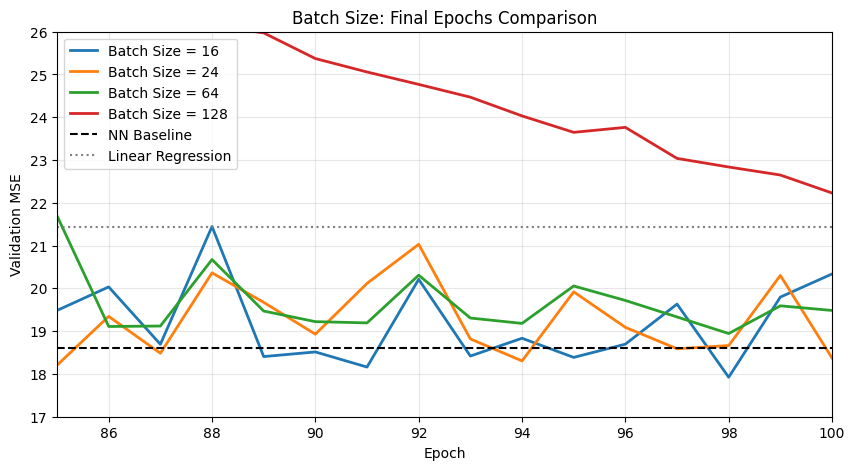

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Compare batch sizes with closer final results
for bs in [16, 24, 64, 128]:

    result = batch_lookup[bs]

    epochs = range(1, len(result["Val Losses"]) + 1)

    plt.plot(
        epochs,
        result["Val Losses"],
        label=f"Batch Size = {bs}",
        linewidth=2
    )

# Neural Network baseline
plt.axhline(
    nn_val_mse,
    color="black",
    linestyle="--",
    label="NN Baseline"
)

# Linear Regression reference
plt.axhline(
    linear_val_mse,
    color="gray",
    linestyle=":",
    label="Linear Regression"
)

# Zoom into the final epochs
plt.xlim(85, 100)
plt.ylim(17, 26)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Batch Size: Final Epochs Comparison")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

## <font color="#3B82F6">Depth and Width</font>


In [32]:
import torch
import torch.nn as nn
import pandas as pd
import time

from torch.utils.data import DataLoader

architecture_results = {}

def run_architecture_experiment(hidden_layers):

    # Same random seed for all experiments
    torch.manual_seed(42)

    generator = torch.Generator().manual_seed(42)

    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    # Build model
    layers = []
    input_size = 4

    for neurons in hidden_layers:
        layers.append(nn.Linear(input_size, neurons))
        layers.append(nn.ReLU())
        input_size = neurons

    layers.append(nn.Linear(input_size, 1))

    model = nn.Sequential(*layers).to(device)

    # Fixed settings
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    start_time = time.perf_counter()

    # Training
    for epoch in range(100):

        model.train()

        for xb, yb in train_loader:

            xb = xb.to(device)
            yb = yb.to(device).reshape(-1, 1)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

        # Evaluation
        model.eval()

        with torch.no_grad():

            train_loss = criterion(
                model(X_train_tensor.to(device)),
                y_train_tensor.to(device).reshape(-1, 1)
            ).item()

            val_loss = criterion(
                model(X_val_tensor.to(device)),
                y_val_tensor.to(device).reshape(-1, 1)
            ).item()

        train_losses.append(train_loss)
        val_losses.append(val_loss)

    training_time = time.perf_counter() - start_time

    return {
        "Architecture": hidden_layers,
        "Train MSE": train_losses[-1],
        "Val MSE": val_losses[-1],
        "Time (s)": training_time,
        "Epochs Completed": 100,
        "Train Losses": train_losses,
        "Val Losses": val_losses
    }


# Display and save each result
def run_and_save_architecture(name, hidden_layers):

    result = run_architecture_experiment(hidden_layers)

    architecture_results[name] = result

    print("Architecture:", result["Architecture"])
    print(f"Training MSE: {result['Train MSE']:.4f}")
    print(f"Validation MSE: {result['Val MSE']:.4f}")
    print(f"Training Time: {result['Time (s)']:.2f} seconds")
    print("Epochs Completed:", result["Epochs Completed"])

Experiment 1 — Width [32, 32]

In [33]:
# Depth & Width Experiment 1

run_and_save_architecture("Experiment 1", [32, 32])

Architecture: [32, 32]
Training MSE: 18.4073
Validation MSE: 19.9251
Training Time: 25.71 seconds
Epochs Completed: 100


Experiment 2 — Width [128, 32]

In [34]:
# Depth & Width Experiment 2

run_and_save_architecture("Experiment 2", [128, 32])

Architecture: [128, 32]
Training MSE: 16.1573
Validation MSE: 17.9696
Training Time: 27.28 seconds
Epochs Completed: 100


Experiment 3 — Width [64, 64]

In [35]:
# Depth & Width Experiment 3

run_and_save_architecture("Experiment 3", [64, 64])

Architecture: [64, 64]
Training MSE: 16.5616
Validation MSE: 18.3218
Training Time: 27.54 seconds
Epochs Completed: 100


Experiment 4 — One Hidden Layer

In [36]:
# Depth & Width Experiment 4

run_and_save_architecture("Experiment 4", [64])

Architecture: [64]
Training MSE: 18.4714
Validation MSE: 19.4936
Training Time: 21.36 seconds
Epochs Completed: 100


Experiment 5 — Three Hidden Layers

In [37]:
# Depth & Width Experiment 5

run_and_save_architecture("Experiment 5", [64, 32, 16])

Architecture: [64, 32, 16]
Training MSE: 16.1674
Validation MSE: 17.9470
Training Time: 29.54 seconds
Epochs Completed: 100


In [38]:
# Depth & Width Results Table

rows = [{
    "Run": "Baseline",
    "Architecture": "[64, 32]",
    "Train MSE": nn_train_mse,
    "Val MSE": nn_val_mse,
    "Time (s)": None,
    "Epochs": 100
}]

for name, result in architecture_results.items():
    rows.append({
        "Run": name,
        "Architecture": str(result["Architecture"]),
        "Train MSE": result["Train MSE"],
        "Val MSE": result["Val MSE"],
        "Time (s)": result["Time (s)"],
        "Epochs": result["Epochs Completed"]
    })

architecture_table = pd.DataFrame(rows)

display(architecture_table.round(4))

,Run,Architecture,Train MSE,Val MSE,Time (s),Epochs
0,Baseline,"[64, 32]",16.7957,18.6084,NaN,100
1,Experiment 1,"[32, 32]",18.4073,19.9251,25.7135,100
2,Experiment 2,"[128, 32]",16.1573,17.9696,27.2784,100
3,Experiment 3,"[64, 64]",16.5616,18.3218,27.5356,100
4,Experiment 4,[64],18.4714,19.4936,21.3553,100
5,Experiment 5,"[64, 32, 16]",16.1674,17.9470,29.5419,100


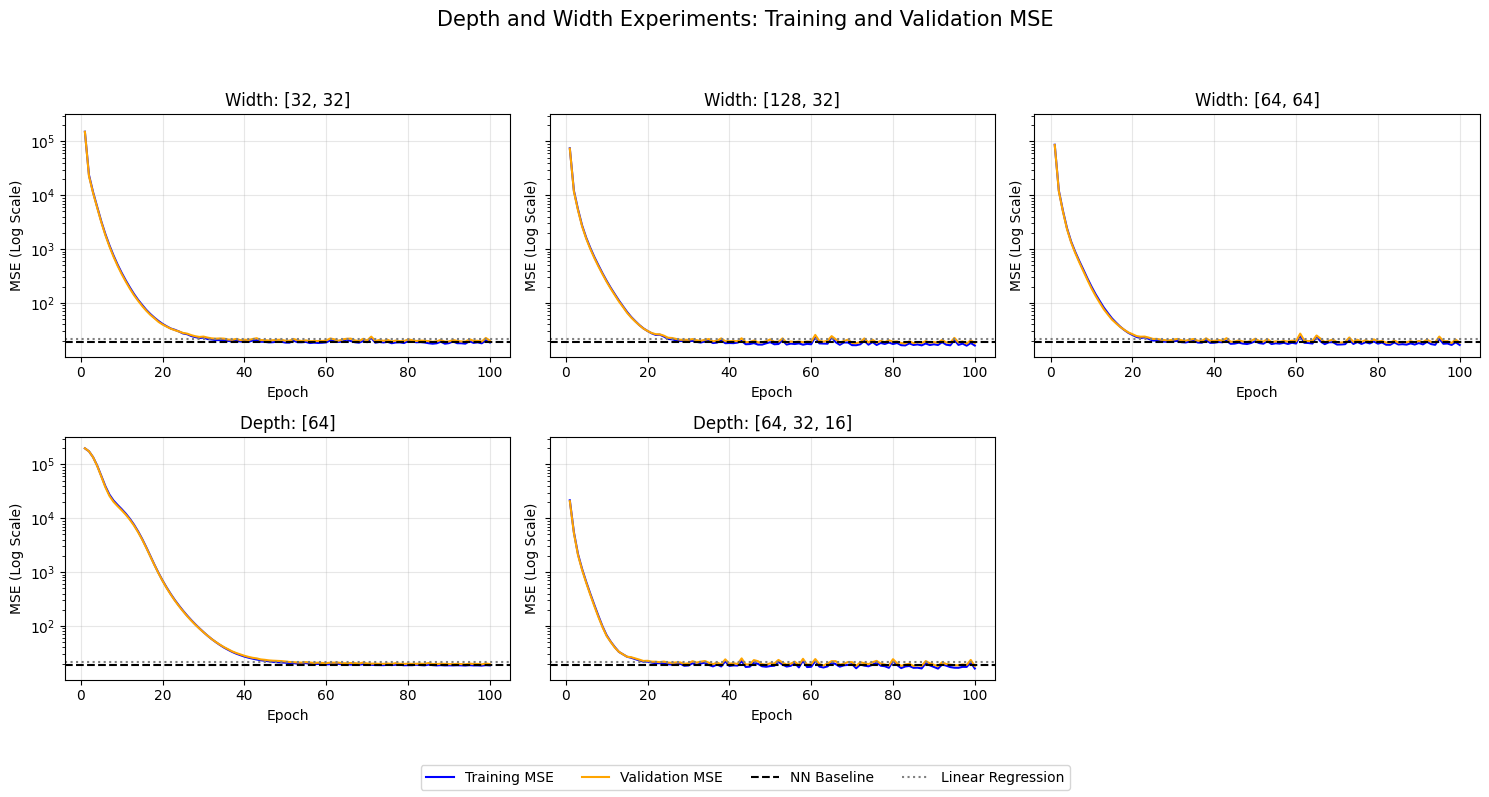

In [45]:
import matplotlib.pyplot as plt

# Depth and Width experiments
experiments = [
    ("Experiment 1", "Width"),
    ("Experiment 2", "Width"),
    ("Experiment 3", "Width"),
    ("Experiment 4", "Depth"),
    ("Experiment 5", "Depth")
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8),
    sharey=True
)

axes = axes.flatten()

for i, (name, category) in enumerate(experiments):

    result = architecture_results[name]

    epochs = range(1, len(result["Train Losses"]) + 1)

    # Training MSE
    axes[i].plot(
        epochs,
        result["Train Losses"],
        color="blue",
        label="Training MSE"
    )

    # Validation MSE
    axes[i].plot(
        epochs,
        result["Val Losses"],
        color="orange",
        label="Validation MSE"
    )

    # Neural Network baseline
    axes[i].axhline(
        nn_val_mse,
        color="black",
        linestyle="--",
        label="NN Baseline"
    )

    # Linear Regression reference
    axes[i].axhline(
        linear_val_mse,
        color="gray",
        linestyle=":",
        label="Linear Regression"
    )

    axes[i].set_title(
        f"{category}: {result['Architecture']}"
    )

    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE (Log Scale)")
    axes[i].set_yscale("log")
    axes[i].grid(True, alpha=0.3)

# Hide empty subplot
axes[5].axis("off")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4
)

fig.suptitle(
    "Depth and Width Experiments: Training and Validation MSE",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()

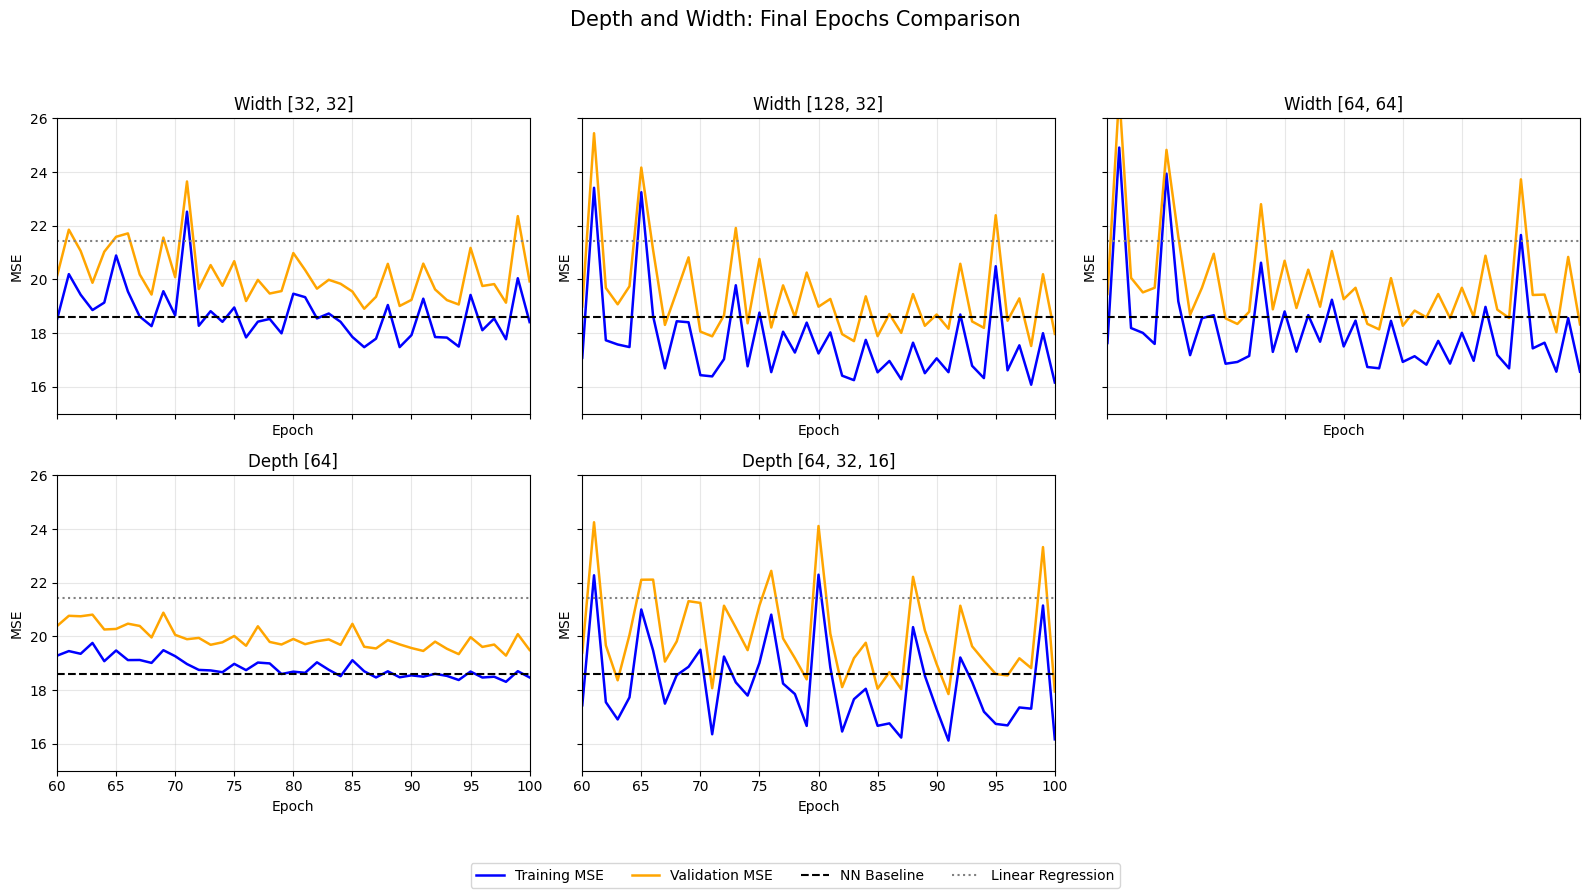

In [46]:
import matplotlib.pyplot as plt

experiments = [
    ("Experiment 1", "Width [32, 32]"),
    ("Experiment 2", "Width [128, 32]"),
    ("Experiment 3", "Width [64, 64]"),
    ("Experiment 4", "Depth [64]"),
    ("Experiment 5", "Depth [64, 32, 16]")
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for i, (name, title) in enumerate(experiments):

    result = architecture_results[name]

    epochs = range(1, len(result["Train Losses"]) + 1)

    # Training MSE
    axes[i].plot(
        epochs,
        result["Train Losses"],
        color="blue",
        linewidth=1.8,
        label="Training MSE"
    )

    # Validation MSE
    axes[i].plot(
        epochs,
        result["Val Losses"],
        color="orange",
        linewidth=1.8,
        label="Validation MSE"
    )

    # NN Baseline
    axes[i].axhline(
        nn_val_mse,
        color="black",
        linestyle="--",
        label="NN Baseline"
    )

    # Linear Regression
    axes[i].axhline(
        linear_val_mse,
        color="gray",
        linestyle=":",
        label="Linear Regression"
    )

    # Zoom into final epochs
    axes[i].set_xlim(60, 100)
    axes[i].set_ylim(15, 26)

    axes[i].set_title(title)
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE")
    axes[i].grid(True, alpha=0.3)

# Hide empty subplot
axes[5].axis("off")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4
)

fig.suptitle(
    "Depth and Width: Final Epochs Comparison",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()

## <font color="#3B82F6">Loss Function</font>


# **Experiment Results Table**

# **Loss Curves & Results Analysis**

# **Best Model Selection**


# **Final Test Evaluation**